# 09 — Playground: change the inputs, and work back from the IPO price

**Question:** 08 says the median simulated world is worth ~$59 a share, and the IPO priced at **$83** (Nov 18), above its $70–78 range. What would the world have to look like for $83 (~$1.5T) to be a fair price? And which inputs move the answer most?

**Short answer**
1. **`montecarlo.py` reproduces 06 and 08** to rounding (per-share percentiles within $0.01), and a full 20,000-world run takes about a second. Change any input in §2's `P` dict (§1–2).
2. **$83 a share is ~$1.48T.** $83 × ~17.8B post-IPO shares (today's 16.4B + 956M IPO + 147M underwriters' option + 313M private placement, final prospectus) ≈ $1.48T; the press's pre-pricing "$1.4T" was the same sum at $78. On today's shares, $83 is **$1.36T**. Because IPO cash comes in with the IPO shares, the test is simply value per share against $83 (§3).
3. **6% of the 20,000 worlds land within $5 of $83 (33% are worth at least $83).** Those worlds have a median ceiling of **~$565B** (about the same as all worlds), **2.16x** revenue per compute dollar (vs 2.0x), ~$510B of revenue in 2030 and ~$1.28T in 2040, with a 13% owner FCF margin. None has a ceiling below ~$360B or efficiency below ~1.74x. With 06's share range, size is no longer what separates them; efficiency is (§3, `09_worlds_at_ipo_price.png`).
4. **One dial at a time,** from a central world worth ~$69 a share, reaching $83 takes **one** of these moves:
   - a **~$730B** ceiling (vs $589B);
   - **2.12x** revenue per compute dollar (vs 2.0x; Q2-2026 was 2.08x, Q3 1.72x);
   - opex down to **~21%** of revenue by 2040 (vs 25%);
   - a **~9.3%** discount rate (beta ~1.0, the market's own risk);
   - **~5.2%** terminal growth, above the Treasury rate (§4).
5. **The map:**
   - **06's costs:** at 2.0x efficiency, $83 needs a ~$720B ceiling; at 2.5x, ~$410B; at 3.0x, ~$320B. At Q3's 1.72x, no ceiling up to $1.5T is enough.
   - **Opex falling to 15% by 2040:** at 2.0x it needs ~$460B; at 1.72x, ~$840B.

   **The IPO price is a world where Anthropic takes a big share of a big market and runs inference more cheaply per dollar of revenue than it does today.** With 06's 30–55% share range, that's the better third of our worlds (§5, `09_ipo_price_map.png`).
6. **By its own compute contracts, Anthropic is worth ~$18–45 a share.** The signed compute can serve ~$262B of revenue in 2030 at Q3-2026's efficiency (1.72x) or ~$325B at Q2's (2.08x). Valued like every other world, that's **~$18** or **~$45** a share ($0.29–0.74T), against $59 for our median world and $83 at the IPO. Anthropic can always buy more compute, so this is a floor on its plan, not a cap. But it's the only forecast the company has put money behind (§6, `09_contracts_view.png`).
7. **Dilution, per share.** New stock grants and donations (7% of revenue, charged as costs) take **~$36 a share**, a third of the value the business would have without them ($105 → $69). The Public Benefit Fund's top-ups (2% more shares per 50% rise from $83) cost only **~1%** on average, because few worlds are worth $125+ (§7).

| § | Question | Chart |
|---|---|---|
| 1 | Does the module reproduce 06 and 08? | — |
| 2 | What do *your* inputs give? (the playground) | inline only |
| 3 | What is $83 in company terms, and which simulated worlds are worth it? | `09_worlds_at_ipo_price.png` |
| 4 | One dial at a time: how far must each move to reach the IPO price? | — |
| 5 | Ceiling × efficiency: where is the IPO price on the map? | `09_ipo_price_map.png` |
| 6 | What is Anthropic worth by its own compute contracts? | `09_contracts_view.png` |
| 7 | What do stock comp, donations and the Public Benefit Fund cost per share? | — |

**The engine is `montecarlo.py`**: 06's simulation (Gompertz revenue curves, costs, cash) and 08's valuation (extension to 2040, CAPM discounting, value per share on today's ~16.4B shares) in one file. Every input and its default is in `mc.PARAMS`. `mc.run(**changes)` draws 20,000 worlds and values them in about a second. `mc.fixed_worlds(ceiling, rev_per_compute)` builds worlds with no randomness, for working backwards. 06 and 08 still hold the explanations, and §1 checks that the module gives their numbers.

**Inputs:** `montecarlo.py` (which reads `data/` like 06 and 08), `data/forecast_worlds.csv` and `data/valuation.csv` (for the check), `data/valuation_inputs.csv` (IPO terms and price).
**Outputs:** two charts. No data hand-off.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from common import *
import montecarlo as mc

B = 1000
ipo_low, ipo_high = mc.IPO
ipo_price = mc.IPO_PRICE
pd.Series(mc.PARAMS).to_frame('default')

,default
ai_share_of_wages,"(0.015, 0.08)"
anthropic_share_of_ai,"(0.3, 0.55)"
ceiling,None
ceiling_growth,0.07
rev_per_compute,"(1.5, 2.5)"
cash_opex_pct,0.25
opex_end,0.25
risk_free,0.0494
erp,0.0441
beta,1.25


## 1. Does the module reproduce 06 and 08?
**Why ask:** a playground is only useful if its defaults give the published numbers. Otherwise you're playing with a different model.

**Method:** run the module with no changes, then compare every world's revenue and owner FCF with 06's `forecast_worlds.csv`, and the value-per-share percentiles with 08's `valuation.csv`. Differences should be rounding only (the CSV keeps 4 decimals).

In [2]:
base = mc.run()
ref = pd.read_csv(DATA / 'forecast_worlds.csv', index_col='world')
gap_06 = max((base[m][y] - ref[f'{m}_{y}']).abs().max() for m in ('revenue', 'owner_fcf')
             for y in ['Q4-2026', '2027', '2028', '2029', '2030'])
ref_08 = load('valuation').query("metric == 'per_share'").set_index('percentile').value
mean_08 = ref_08.pop('mean')
gap_08 = (base['worlds'].per_share.quantile([0.1, 0.25, 0.5, 0.75, 0.9]).values - ref_08.values)
print(f'Largest gap vs 06, any world and year: ${gap_06:.5f}M;  vs 08 percentiles: ${np.abs(gap_08).max():.3f}/share')
assert gap_06 < 0.01 and np.abs(gap_08).max() < 0.05 and abs(base['worlds'].per_share.mean() - mean_08) < 0.05, 'montecarlo.py has drifted from 06/08: re-run them or fix the module'
mc.summary(base)

Largest gap vs 06, any world and year: $0.00005M;  vs 08 percentiles: $0.005/share
discount rate 10.45%; mean value per share $69.47; worlds worth ≥ $83 (IPO price): 33%; run out of cash: 0.0%


,P10,P25,P50,P75,P90
"ceiling today, $B",293.21,381.04,571.34,875.20,1157.56
"revenue 2030, $B",305.62,382.63,524.11,723.72,907.31
"revenue last year, $B",682.02,880.05,1307.59,1977.60,2592.97
"owner FCF margin, last year",0.00,0.05,0.10,0.15,0.17
"lowest cash, $B",134.86,135.82,136.62,137.40,138.06
"equity value, $B",168.71,520.11,967.87,1602.82,2342.42
"value per share, $",10.30,31.76,59.10,97.87,143.03


**What this shows:** the module matches 06 and 08 to rounding. The table is 08's answer again: median ~$59 a share, and 33% of worlds worth the $83 IPO price. "Lowest cash" runs to 2040 rather than 06's 2030; no world runs out in either.

**Next:** your turn.

## 2. What do *your* inputs give? (the playground)
**Why ask:** every number this model produces comes from a handful of inputs. Before changing them, it helps to know which come from Anthropic's filing, which are the company's own claims, and which are ours.

**The inputs, in plain English.** *S-1* = a fact in the filing. *Anthropic* = the company's own estimate or framing in the filing (unaudited, and written to sell the stock). *Ours* = our assumption where the filing is silent. *Market* = outside market data.

| Input | Default | From | What Anthropic says, and yardsticks |
|---|---|---|---|
| **The prize:** what knowledge workers are paid | >$40T a year | Anthropic | "the work that knowledge workers perform represented more than $40 trillion in economic value globally in 2025," and there will be >1B knowledge workers by 2028. Anthropic's own estimate from government wage data. |
| **AI's share of that pay** (`ai_share_of_wages`) | 1.5%–8% ($0.6–3.2T a year; ~$50–270 a month per knowledge worker) | Ours | The S-1 never says. Yardstick: cloud computing took 20 years to reach $1.9T, ~5% of $40T (S-1). Each doubling (2% → 4% → 8%) gets equal odds. |
| **Anthropic's share of AI spending** (`anthropic_share_of_ai`) | 30%–55% | Ours | The S-1 gives no market share. We assume Anthropic stays the leading vendor of AI for knowledge work: from first among several frontier labs and the cloud giants to about half the market. Its own compute contracts imply less (§6). |
| = **Revenue ceiling** today | ~$180B–$1.8T a year, ~$590B in the middle (~$49 a month per knowledge worker) | calculated | Anthropic's compute contracts are sized for **~$236B** at Q3 efficiency, ~$304B at Q2's (§6; ~$20–25 a month per worker), below ~88–97% of our worlds. The **$83 IPO price** needs **~$730B** at 2.0x efficiency (§4): ~$60 a month from every knowledge worker on earth, e.g. 4% of pay going to AI and Anthropic taking 46% of it. |
| Ceiling growth (`ceiling_growth`) | 7% a year | S-1 | IT spending grew ~7% a year from 2006 to 2025. |
| How fast revenue approaches the ceiling | fitted | S-1 | Fitted to the last six quarters of growth (06 §2). Not a free choice. |
| **Revenue per $1 of compute** (`rev_per_compute`) | $1.50–2.50 | Ours, anchored on S-1 | $1.72 in Q3-2026, $2.08 in Q2-2026. Cheaper chips push it up; price cuts push it down. Compute never drops below the take-or-pay contracts (S-1). |
| **Other cash costs**: sales, partner fees, salaries (`cash_opex_pct`, `opex_end`) | 25% of revenue, flat to 2040 | Ours | ~28% in Q3-2026 (03). Big software companies get lower with scale. We don't assume that. |
| New stock pay (`sbc_new_grants_pct`) | 4% of revenue | Ours | 6.3% in Q3-2026, including grants already made (those are in the 16.4B share count). |
| Donations (`donations_pct`) | 3% of revenue | Ours | 6% in 9M-2026, lumpy; the company says it will grow. |
| Owned equipment (`capex_pct`) | 4% of revenue | Ours | 8.7% in 9M-2026, partly rent paid in advance. Most compute is rented, and that's already in the compute line. |
| Tax (`tax_rate`) | 21% of profits | Ours | US federal rate. Ignores past losses that would shelter tax. |
| **Discount rate** (`risk_free`, `beta`, `erp`) | ~10.5% | Market | Treasury rate + listed software's risk × the stock market's extra return (08 §1). |
| Growth after 2040 (`terminal_growth`) | 3% a year | Ours | Below the Treasury rate: no company outgrows the economy forever. |

**The quiet part:** Anthropic supplies the $40T. Every number between that and its revenue in 2030 is someone's guess. The S-1 doesn't give one; its compute contracts reveal one (~$236B); the IPO price implies another (~$730B). Ours (~$590B in the middle) sits closer to the IPO price than to the contracts. §6 values the contracts' view on its own.

**Which inputs matter?** Move each one to a plausible low and high, keep everything else at its default, and see how far the median world's value per share moves.

In [3]:
beta_internet = load('valuation_inputs').set_index('item').value['beta_software_internet']
ALT = {  # input: (low case, high case), each a plausible alternative to the default
    'ai_share_of_wages':     ((0.012, 0.06), (0.02, 0.11)),
    'anthropic_share_of_ai': ((0.15, 0.35), (0.50, 0.75)),   # low: the old default
    'ceiling_growth':        (0.05, 0.09),
    'rev_per_compute':       ((1.25, 2.0), (2.0, 3.0)),
    'opex_end':              (0.30, 0.15),
    'sbc_new_grants_pct':    (0.063, 0.02),   # high: Q3-2026's total
    'donations_pct':         (0.06, 0.0),     # high: 9M-2026's level
    'capex_pct':             (0.087, 0.02),   # high: 9M-2026's level
    'tax_rate':              (0.25, 0.15),
    'beta':                  (beta_internet, 1.0),   # internet software vs the market itself
    'terminal_growth':       (0.02, 0.04),
    'speed_noise':           (0.0, 2.0),
}
med = lambda **ch: mc.run(**ch)['worlds'].per_share.median()
swing = pd.DataFrame([{'input': k, 'low case': str(lo), '$/share at low': med(**{k: lo}),
                       'high case': str(hi), '$/share at high': med(**{k: hi})} for k, (lo, hi) in ALT.items()]).set_index('input')
swing['swing, $/share'] = (swing['$/share at high'] - swing['$/share at low']).abs()
print(f"Default median: ${base['worlds'].per_share.median():.2f} a share")
swing.sort_values('swing, $/share', ascending=False).round(2)

Default median: $59.10 a share


,low case,$/share at low,high case,$/share at high,"swing, $/share"
input,,,,,
rev_per_compute,"(1.25, 2.0)",14.71,"(2.0, 3.0)",107.90,93.19
anthropic_share_of_ai,"(0.15, 0.35)",36.56,"(0.5, 0.75)",82.32,45.76
opex_end,0.3,45.24,0.15,89.50,44.26
capex_pct,0.087,35.57,0.02,69.87,34.30
ai_share_of_wages,"(0.012, 0.06)",47.83,"(0.02, 0.11)",75.96,28.13
donations_pct,0.06,47.07,0.0,71.91,24.85
beta,1.59,48.91,1.0,69.85,20.94
ceiling_growth,0.05,50.95,0.09,68.94,17.99
sbc_new_grants_pct,0.063,49.90,0.02,67.66,17.76


**What this shows:** efficiency (revenue per compute dollar) is the biggest single dial by far, then Anthropic's share of AI (the low case is our earlier 15–35% default), how far opex falls with scale, capex, AI's share of wages and donations. The cost lines matter more than they look: the long-run margin is thin (~10% owner FCF in 2040, 08 §2), so **every 1% of revenue a cost takes, every year, is worth ~$4–5 a share**. Terminal growth and the randomness in speed barely move the answer. At the low end of efficiency, values hit zero: see 08 §3 for why.

**How to use the playground:** put any `PARAMS` key in the `P` dict below and re-run the cell. Every key, its default and its source are in `montecarlo.py`.

| Key | Default | What it does |
|---|---|---|
| `ai_share_of_wages`, `anthropic_share_of_ai` | (1.5%, 8%), (15%, 35%) | size the revenue ceiling: $40T × AI's share × Anthropic's share |
| `ceiling` | None | set the ceiling range directly, e.g. `(400e3, 900e3)` = $400–900B a year |
| `rev_per_compute` | (1.5, 2.5) | revenue per $1 of compute: inference efficiency net of price cuts |
| `speed_noise` | 1.0 | 0 = every world grows at exactly the speed fitted to the history |
| `cash_opex_pct`, `opex_end` | 25%, 25% | cash opex through 2030, and where it ends up by 2040 |
| `sbc_new_grants_pct`, `donations_pct`, `capex_pct` | 4%, 3%, 4% | future dilution, donations and owned equipment, charged as costs |
| `beta`, `discount_rate` | 1.25, None | risk; `discount_rate` overrides CAPM |
| `terminal_growth`, `last_year` | 3%, 2040 | the perpetuity, and when it starts |

To pin a single world, give each range the same value at both ends, e.g. `ceiling=(500e3, 500e3)`, `rev_per_compute=(2, 2)`, `speed_noise=0`.

discount rate 12.11%; mean value per share $58.67; worlds worth ≥ $83 (IPO price): 26%; run out of cash: 0.0%


,P10,P25,P50,P75,P90
"ceiling today, $B",343.89,448.24,671.74,1029.03,1363.52
"revenue 2030, $B",347.85,434.90,592.00,811.67,1017.23
"revenue last year, $B",797.24,1029.17,1529.88,2313.50,3038.30
"owner FCF margin, last year",-0.02,0.02,0.08,0.12,0.14
"lowest cash, $B",134.96,135.91,136.76,137.55,138.22
"equity value, $B",0.00,344.45,821.21,1395.84,2094.60
"value per share, $",0.00,21.03,50.14,85.23,127.89


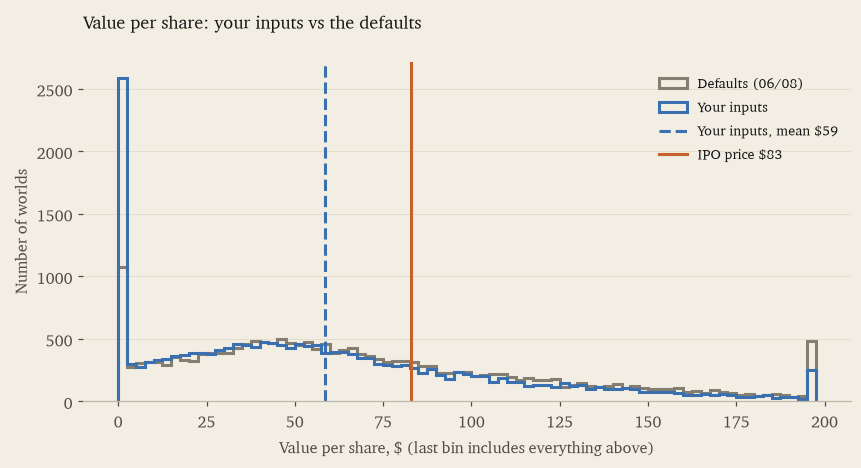

In [4]:
P = dict(  # <- your changes here, e.g. opex_end=0.15, beta=1.5, rev_per_compute=(1.8, 3.0)
    # Ranges (low, high) only for ai_share_of_wages, anthropic_share_of_ai, rev_per_compute, ceiling; the rest take one number
    anthropic_share_of_ai=(0.35, 0.65),   # a range is fine here: each world draws its own
    terminal_growth=0.055,   # one number, not a range (you had 4-7%; this is the middle)
    beta=1.625,              # you had 1.5-1.75
    sbc_new_grants_pct=0.07, # you had 6-8%
)
mine = mc.run(**P)
display(mc.summary(mine))

fig, ax = plt.subplots(figsize=(9, 4))
bins = np.arange(0, 200, 2.5)
for res, label, col in ((base, 'Defaults (06/08)', NEUTRAL), (mine, 'Your inputs', SERIES[0])):
    ax.hist(res['worlds'].per_share.clip(upper=bins[-1] - 0.01), bins=bins, histtype='step', lw=2, color=col, label=label)
my_mean = mine['worlds'].per_share.mean()
ax.axvline(my_mean, color=SERIES[0], lw=2, ls='--', label=f'Your inputs, mean ${my_mean:.0f}')
ax.axvline(ipo_price, color=SERIES[1], lw=2, label=f'IPO price ${ipo_price:.0f}')
ax.set_xlabel('Value per share, $ (last bin includes everything above)')
ax.set_ylabel('Number of worlds')
ax.legend(loc='upper right', fontsize=9)
ax.set_title('Value per share: your inputs vs the defaults', fontsize=12)
plt.show()

**What this shows:** with `P` empty, the two lines sit on top of each other. Edit `P` and re-run the cell: the blue histogram and the dashed line (your mean value per share) move to your inputs. The summary above it has the percentiles, your mean, and the share of worlds worth at least the $83 IPO price. This chart isn't saved: it changes every time you play.

**Next:** work backwards. Start with what $83 means for the whole company.

## 3. What is $83 in company terms, and which simulated worlds are worth it?
**Why ask:** headline valuations count the IPO's new shares, while 08 values today's shares. Before comparing, put them in the same units.

**Method:** a company valuation is price × shares. After the IPO there are today's ~16.4B fully diluted shares, plus 956M sold by Anthropic in the IPO (final prospectus), plus up to 147M more if the underwriters take their option, plus the $26B private placement at $83 (313M shares). **New shares sold at a fair price don't change value per share**: the cash comes in with them. So the test of the headline is simply whether a share is worth $83. Then we take the simulated worlds whose value lands within $5 of $83 and compare their inputs with all 20,000.

In [5]:
X = load('valuation_inputs').set_index('item').value
def post_ipo_shares(price, option=True):
    """Today's fully diluted shares + new IPO shares + private placement (selling holders' shares are already in today's count)."""
    return (mc.FD_SHARES + (X['ipo_shares_offered_company'] + option * X['ipo_underwriter_option']) * 1e6
            + X['ipo_private_placement'] * 1e6 / price)
for price in (ipo_high, ipo_price):
    n = post_ipo_shares(price)
    print(f'${price:.0f}/share x {n/1e9:.2f}B shares (incl. option) = ${price * n / 1e12:.2f}T; '
          f'on today\'s {mc.FD_SHARES/1e9:.1f}B shares = ${price * mc.FD_SHARES / 1e12:.2f}T')

w = base['worlds']
band = (ipo_price - 5, ipo_price + 5)                 # worlds within $5 of the price
at_ipo = w.per_share.between(*band)
cols = {'ceiling': 'ceiling today, $B', 'rev_per_compute': 'revenue per compute $', 'speed': 'speed (share of gap per quarter)',
        'revenue_2030': 'revenue 2030, $B', 'revenue_last': 'revenue 2040, $B', 'owner_fcf_margin_last': 'owner FCF margin 2040'}
cmp = pd.DataFrame({'all worlds': w[list(cols)].median(), f'worlds worth ${band[0]:.0f}–{band[1]:.0f} ({at_ipo.mean():.0%})': w.loc[at_ipo, list(cols)].median()}).rename(index=cols)
cmp.loc[[i for i in cmp.index if '$B' in i]] /= B
cmp.round(2)

$78/share x 17.81B shares (incl. option) = $1.39T; on today's 16.4B shares = $1.28T
$83/share x 17.79B shares (incl. option) = $1.48T; on today's 16.4B shares = $1.36T


,all worlds,worlds worth $78–88 (6%)
"ceiling today, $B",571.34,564.64
revenue per compute $,2.01,2.16
speed (share of gap per quarter),0.14,0.14
"revenue 2030, $B",524.11,513.50
"revenue 2040, $B",1307.59,1284.79
owner FCF margin 2040,0.10,0.13


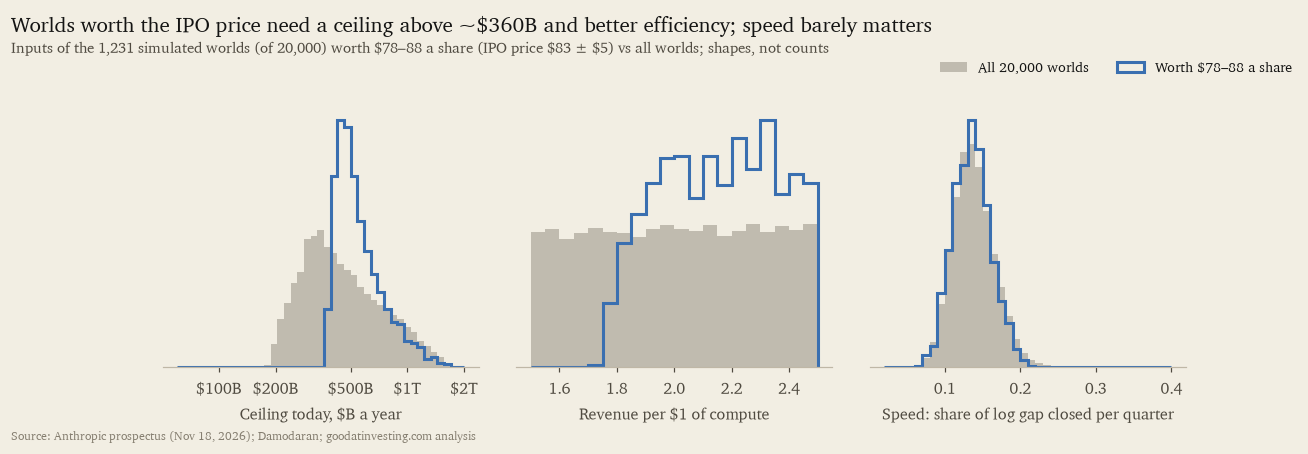

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(12, 4))
panels = (('ceiling', 'Ceiling today, $B a year', 1 / B, np.geomspace(60, 2000, 44), True),
          ('rev_per_compute', 'Revenue per $1 of compute', 1, np.linspace(1.5, 2.5, 21), False),
          ('speed', 'Speed: share of log gap closed per quarter', 1, np.linspace(0.02, 0.4, 39), False))
for ax, (c, label, scale, bins, logx) in zip(axes, panels):
    ax.hist(w[c] * scale, bins=bins, density=True, color=NEUTRAL, alpha=0.45, label='All 20,000 worlds')
    ax.hist(w.loc[at_ipo, c] * scale, bins=bins, density=True, histtype='step', lw=2, color=SERIES[0],
            label=f'Worth ${band[0]:.0f}–{band[1]:.0f} a share')
    if logx:
        ax.set_xscale('log')
        ax.set_xticks([100, 200, 500, 1000, 2000], ['$100B', '$200B', '$500B', '$1T', '$2T'])
        ax.minorticks_off()
    ax.set_yticks([])
    ax.set_xlabel(label)
fig.legend(*axes[0].get_legend_handles_labels(), loc='upper right', bbox_to_anchor=(0.99, 0.9), ncols=2, fontsize=9)
fig.suptitle(f'Worlds worth the IPO price need a ceiling above ~$360B and better efficiency; speed barely matters',
             x=0.01, ha='left', fontsize=14)
fig.text(0.01, 0.885, f'Inputs of the {at_ipo.sum():,} simulated worlds (of {len(w):,}) worth ${band[0]:.0f}–{band[1]:.0f} a share (IPO price ${ipo_price:.0f} ± $5) vs all worlds; shapes, not counts',
         color=INK2, fontsize=10)
fig.subplots_adjust(top=0.76, bottom=0.17, wspace=0.12)
source(fig, 'Source: Anthropic prospectus (Nov 18, 2026); Damodaran; goodatinvesting.com analysis')
save(fig, '09_worlds_at_ipo_price.png')
plt.show()

**What this shows** (`09_worlds_at_ipo_price.png`): every world priced like the IPO has a ceiling above ~$360B a year, and the middle half sit between ~$470B and ~$760B, about where all of 06's worlds are. Efficiency separates them more: none is below ~1.74x revenue per compute dollar, and 90% are above ~1.88x. Speed hardly separates them. In plain terms: **with 06's share range, the IPO price is a bet on serving cost more than on market size, and not on how fast the next few quarters grow.**

**Next:** that mixes every dial at once. Take them one at a time.

## 4. One dial at a time: how far must each move to reach the IPO price?
**Method:** start from a **central world** with every input at the middle of its range: AI's share of wages 3.5% (the log-midpoint of 1.5–8%), Anthropic's share 42.5%, so a ceiling of ~$589B, 2.0x revenue per compute dollar, and the speed fitted to that ceiling, with no noise. Then move **one** dial while holding the rest, and find the value that makes the central world worth $83 a share, the IPO price (and $78, the top of the marketed range). Each value comes from evaluating a fine grid and interpolating.

In [7]:
c0 = mc._K['knowledge_work_value'] * np.sqrt(np.prod(mc.PARAMS['ai_share_of_wages'])) * np.mean(mc.PARAMS['anthropic_share_of_ai'])
rpc0 = np.mean(mc.PARAMS['rev_per_compute'])

def central(ceiling=c0, rpc=rpc0, **changes):
    """Value per share of the central world(s), with any PARAMS changed. ceiling / rpc can be arrays."""
    return mc.simulate(mc.fixed_worlds(ceiling, rpc), {**mc.PARAMS, **changes})['worlds'].per_share.values

def solve(grid, values, target):
    """Dial setting that gives `target` $/share, if it's reachable on the grid (values must be monotonic)."""
    order = np.argsort(values)
    return np.interp(target, values[order], grid[order]) if values.min() <= target <= values.max() else np.nan

v0 = central()[0]
print(f'Central world: ceiling ${c0/B:,.0f}B, {rpc0:.1f}x revenue per compute $, worth ${v0:.2f} a share')

DIALS = {  # dial: (grid, how to evaluate, default, unit)
    'Ceiling today, $B a year':     (np.geomspace(100e3, 3e6, 400), lambda g: central(ceiling=g), c0, 1 / B),
    'Revenue per $1 of compute':     (np.linspace(1.5, 5, 400), lambda g: central(rpc=g), rpc0, 1),
    'Cash opex by 2040, % of rev':   (np.linspace(0.25, 0, 101), lambda g: np.array([central(opex_end=x)[0] for x in g]), 0.25, 100),
    'Discount rate, %':              (np.linspace(0.13, 0.05, 161), lambda g: np.array([central(discount_rate=x)[0] for x in g]), base['discount_rate'], 100),
    'Terminal growth, %':            (np.linspace(0, 0.07, 141), lambda g: np.array([central(terminal_growth=x)[0] for x in g]), 0.03, 100),
    'Beta':                          (np.linspace(1.6, 0.3, 131), lambda g: np.array([central(beta=x)[0] for x in g]), mc.PARAMS['beta'], 1),
}
rows = {}
for dial, (grid, f, default, unit) in DIALS.items():
    vals = f(grid)
    rows[dial] = {'default': default * unit, f'for ${ipo_high:.0f} (top of range)': solve(grid, vals, ipo_high) * unit,
                  f'for ${ipo_price:.0f} (IPO price)': solve(grid, vals, ipo_price) * unit, 'best on grid, $/share': vals.max()}
one_dial = pd.DataFrame(rows).T
one_dial.round(2)

Central world: ceiling $589B, 2.0x revenue per compute $, worth $69.46 a share


,default,for $78 (top of range),for $83 (IPO price),"best on grid, $/share"
"Ceiling today, $B a year",588.90,678.17,731.64,275.93
Revenue per $1 of compute,2.00,2.08,2.12,204.14
"Cash opex by 2040, % of rev",25.00,22.41,20.89,151.82
"Discount rate, %",10.45,9.68,9.30,277.39
"Terminal growth, %",3.00,4.57,5.22,106.39
Beta,1.25,1.07,0.99,166.39


**What this shows:** the central world is worth ~$69, below the $70–78 range, so each dial needs a moderate move to reach $83.
- **Ceiling ~$730B a year** (vs $589B): about 1.8% of the S-1's $40T of knowledge-work wages going to Anthropic alone.
- **2.12x revenue per compute dollar** (vs 2.0x). Q3-2026 was 1.72x and Q2 2.08x, so this means beating Q2's best, sustained, net of price cuts.
- **Opex at ~21% of revenue by 2040** (vs 25%).
- **A ~9.3% discount rate, or beta ~1.0**: Anthropic priced as no riskier than the market.
- **~5.2% terminal growth**, above the Treasury rate forever.

The central world is itself an optimistic world: it assumes Anthropic takes ~42% of AI spending. §6 asks what the company's own contracts say.

**Next:** the two business dials, ceiling and efficiency, together.

## 5. Ceiling × efficiency: where is the IPO price on the map?
**Method:** a grid of 60 × 60 central-style worlds, each with its own ceiling ($100B–$1.5T) and revenue per compute dollar (1.5–3.5x), speed fitted to the ceiling, every other input at its default. Shade each by value per share, then draw the line where it equals the $83 IPO price. Draw it twice: with opex at 25% forever (06's assumption), and with opex falling to 15% by 2040. The box is 06's simulated range (ceiling P10–P90, efficiency 1.5–2.5x).

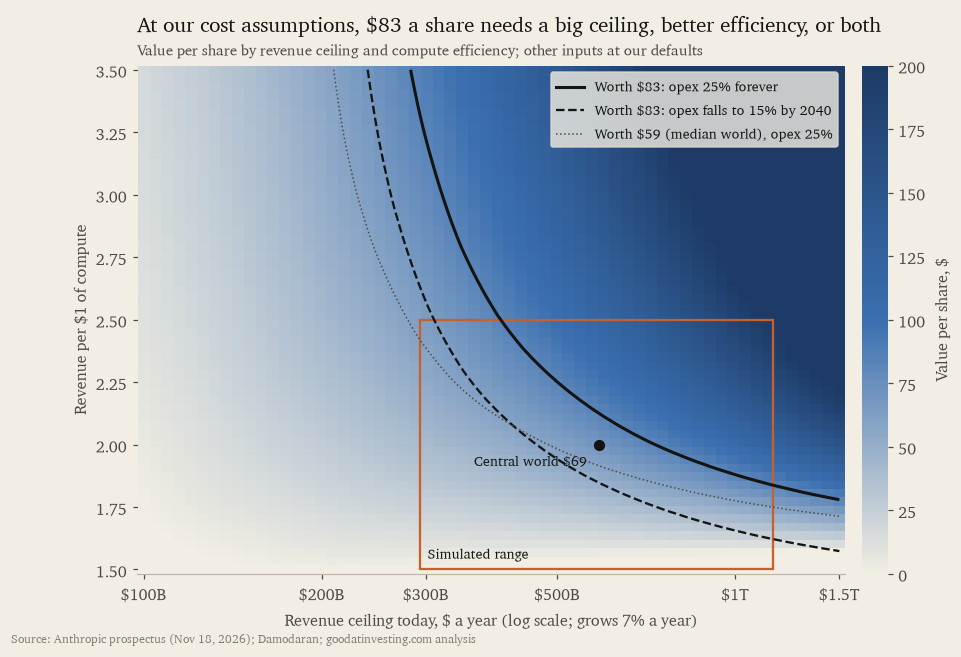

opex 25% by 2040 -> ceiling needed for $83: 1.7x: $nanB, 2.0x: $719B, 2.5x: $406B, 3.0x: $320B
opex 15% by 2040 -> ceiling needed for $83: 1.7x: $844B, 2.0x: $456B, 2.5x: $312B, 3.0x: $262B


In [8]:
cg = np.geomspace(100e3, 1.5e6, 60)
rg = np.linspace(1.5, 3.5, 60)
C, Rr = np.meshgrid(cg, rg)
value_map = {o: central(C.ravel(), Rr.ravel(), opex_end=o).reshape(C.shape) for o in (0.25, 0.15)}

ramp = LinearSegmentedColormap.from_list('seq', [SURFACE, SERIES[0], DARK])
fig, ax = plt.subplots(figsize=(10, 6))
mesh = ax.pcolormesh(C / B, Rr, value_map[0.25], cmap=ramp, vmin=0, vmax=200, shading='auto')
cs1 = ax.contour(C / B, Rr, value_map[0.25], levels=[ipo_price], colors=INK, linewidths=2)
cs2 = ax.contour(C / B, Rr, value_map[0.15], levels=[ipo_price], colors=INK, linewidths=1.5, linestyles='--')
med08 = w.per_share.median()
cs3 = ax.contour(C / B, Rr, value_map[0.25], levels=[med08], colors=INK2, linewidths=1, linestyles=':')
lo, hi = w.ceiling.quantile([0.1, 0.9]) / B
ax.add_patch(plt.Rectangle((lo, 1.5), hi - lo, 1.0, fill=False, ec=SERIES[1], lw=1.5))
ax.text(lo * 1.03, 1.53, "Simulated range", color=INK, fontsize=9, va='bottom')
ax.scatter([c0 / B], [rpc0], color=INK, s=40, zorder=3)
ax.annotate(f'Central world ${v0:.0f}', (c0 / B, rpc0), xytext=(-8, -14), textcoords='offset points', ha='right', fontsize=9, color=INK)
ax.plot([], [], color=INK, lw=2, label=f'Worth ${ipo_price:.0f}: opex 25% forever')
ax.plot([], [], color=INK, lw=1.5, ls='--', label=f'Worth ${ipo_price:.0f}: opex falls to 15% by 2040')
ax.plot([], [], color=INK2, lw=1, ls=':', label=f'Worth ${med08:.0f} (median world), opex 25%')
ax.legend(loc='upper right', fontsize=9, frameon=True, facecolor=SURFACE, edgecolor=GRID)
ax.set_xscale('log')
ax.set_xticks([100, 200, 300, 500, 1000, 1500], ['$100B', '$200B', '$300B', '$500B', '$1T', '$1.5T'])
ax.minorticks_off()
ax.grid(False)
ax.set_xlabel('Revenue ceiling today, $ a year (log scale; grows 7% a year)')
ax.set_ylabel('Revenue per $1 of compute')
cb = fig.colorbar(mesh, ax=ax, pad=0.02)
cb.set_label('Value per share, $')
cb.outline.set_visible(False)
ax.set_title(f'At our cost assumptions, ${ipo_price:.0f} a share needs a big ceiling, better efficiency, or both')
subtitle(ax, 'Value per share by revenue ceiling and compute efficiency; other inputs at our defaults')
source(fig, 'Source: Anthropic prospectus (Nov 18, 2026); Damodaran; goodatinvesting.com analysis')
save(fig, '09_ipo_price_map.png')
plt.show()

# Points on the IPO-price line, to quote in the text
for o in (0.25, 0.15):
    print(f"opex {o:.0%} by 2040 -> ceiling needed for ${ipo_price:.0f}: "
          + ', '.join(f'{r:.1f}x: ${solve(cg, value_map[o][np.abs(rg - r).argmin()], ipo_price)/B:,.0f}B' for r in (1.72, 2.0, 2.5, 3.0)))

**What this shows** (`09_ipo_price_map.png`): darker means more value per share. The solid line is where a world is worth $83 at 06's costs; everything above and to the right of it is worth more.
- **06's box straddles the line.** Its right side clears $83: a ceiling above ~$410B at 2.5x efficiency, or above ~$720B at 2.0x. That's where 08's 33% of worlds come from. The box (ceiling P10–P90, ~$290B–$1.16T) sits mostly in big-market territory, so efficiency decides which side of the line a world lands on.
- **At Q3's actual 1.72x, no ceiling up to $1.5T reaches $83** under 06's costs. The take-or-pay compute bill and 25% opex leave too thin a margin for any market size to fix.
- **Opex leverage moves the line a lot** (dashed): at 2.0x, the ceiling needed falls from ~$720B to ~$460B. The opex assumption is the cheapest place for an optimist to find value, and worth checking against what mature software companies actually spend.
- The dotted line is 08's median value (~$59), running through the middle of the box.

**Where the IPO price lands:** along the solid line, from a ~$410B ceiling at 2.5x to a ~$720B ceiling at 2.0x, or a smaller ceiling if opex falls. With 06's share range, that's the upper-right part of the box: the price needs Anthropic to take a large share of AI spending *and* run at Q2's efficiency or better.

**Next:** we've asked what the market's price implies. What does the company's own plan imply?

## 6. What is Anthropic worth by its own compute contracts?
**Why ask:** the S-1 gives no revenue forecast, but the compute contracts are one, written in dollars. Nobody signs up for ~$130B a year of take-or-pay compute without a revenue plan to pay for it (06 §3–4). So take the contracts at their word: what revenue are they sized for, and what is a company with that revenue worth?

**Method:**
1. **Revenue the contracts can serve** = committed compute × revenue per compute dollar (03 §2). Two efficiencies from the S-1: Q3-2026's **1.72x** (the latest) and Q2-2026's **2.08x** (the best so far).
2. **The ceiling that matches it:** find the Gompertz ceiling whose 2029 revenue equals the contracts' 2029 revenue, with the speed fitted to the history (06 §4 does this at 1.72x).
3. **Value it** with the same model as every other world: same costs, the same extension to 2040 and the same discount rate (08). No randomness: one world per efficiency.

The calculation lives in `mc.contract_worlds()`, so 10 and `research.ipynb` value the same two worlds.

**What this is not:** a cap. The contracts are what Anthropic has signed so far, and it can always buy more compute, at spot prices if it has to (07 §3). Read this as the company's **committed** forecast: what it has been willing to stake money on.

In [9]:
cw = mc.contract_worlds()                     # in montecarlo.py, so 10 and research.ipynb use the same worlds
own, own_rev = {}, {}
for label, one in cw.items():
    ow = one['worlds'].iloc[0]
    own_rev[label] = one['revenue'].iloc[0]
    own[label] = {'ceiling today, $B': ow.ceiling / B, 'revenue per compute $': ow.rev_per_compute,
                  **{f'revenue {y}, $B': own_rev[label][y] / B for y in ('2027', '2028', '2030', '2040')},
                  'owner FCF margin 2040': ow.owner_fcf_margin_last, 'equity value, $T': ow.equity / 1e6,
                  'value per share, $': ow.per_share, 'share of our worlds worth less': (w.per_share < ow.per_share).mean(),
                  'share of our ceilings below': (w.ceiling < ow.ceiling).mean()}
own = pd.DataFrame(own)
own['Our median world'] = [w.ceiling.median() / B, w.rev_per_compute.median(),
                           *[base['revenue'][y].median() / B for y in ('2027', '2028', '2030', '2040')],
                           w.owner_fcf_margin_last.median(), w.equity.median() / 1e6, w.per_share.median(), 0.5, 0.5]
own.round(2)

,Contracts at 1.72x (Q3-2026),Contracts at 2.08x (Q2-2026),Our median world
"ceiling today, $B",236.17,303.85,571.34
revenue per compute $,1.72,2.08,2.01
"revenue 2027, $B",120.36,131.24,155.48
"revenue 2028, $B",179.86,208.96,284.12
"revenue 2030, $B",262.15,324.75,524.11
"revenue 2040, $B",555.00,709.59,1307.59
owner FCF margin 2040,0.04,0.12,0.10
"equity value, $T",0.29,0.74,0.97
"value per share, $",17.55,45.48,59.10
share of our worlds worth less,0.15,0.38,0.50


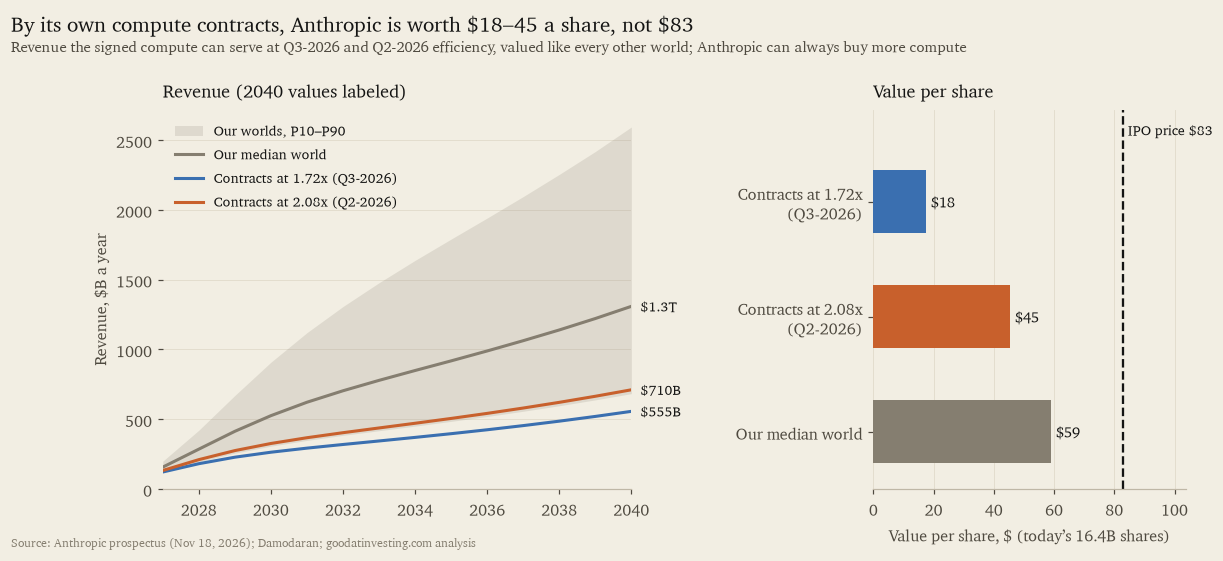

In [10]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5), gridspec_kw={'width_ratios': [1.5, 1]})
years = base['revenue'].columns[1:]                                              # 2027 ... 2040
x = years.astype(int)
p10, p50, p90 = (base['revenue'][years].quantile(q) / B for q in (0.1, 0.5, 0.9))
ax1.fill_between(x, p10, p90, color=NEUTRAL, alpha=0.18, lw=0, label='Our worlds, P10–P90')
ax1.plot(x, p50, color=NEUTRAL, label='Our median world')
for (label, rev), col in zip(own_rev.items(), SERIES):
    ax1.plot(x, rev[years] / B, color=col, label=label)
    ax1.annotate(f'${rev["2040"] / B:,.0f}B', (2040, rev['2040'] / B), xytext=(6, 0), textcoords='offset points',
                 va='center', fontsize=9, color=INK, annotation_clip=False)
ax1.annotate(f'${p50["2040"] / B:.1f}T', (2040, p50['2040']), xytext=(6, 0), textcoords='offset points', va='center',
             fontsize=9, color=INK, annotation_clip=False)
ax1.set_ylabel('Revenue, $B a year')
ax1.set_xlim(2027, 2040)
ax1.legend(loc='upper left', fontsize=9)
ax1.set_title('Revenue (2040 values labeled)', fontsize=11.5, pad=8)

rows = list(own.columns)
vals = own.loc['value per share, $']
cols = SERIES[:len(own_rev)] + [NEUTRAL]
ax2.barh(range(len(rows)), vals, color=cols, height=0.55)
for i, v in enumerate(vals):
    ax2.text(v + 1.5, i, f'${v:.0f}', va='center', fontsize=10, color=INK)
ax2.axvline(ipo_price, color=INK, lw=1.5, ls='--')
ax2.text(ipo_price + 1.5, -0.55, f'IPO price ${ipo_price:.0f}', fontsize=9, color=INK, va='bottom')
ax2.set_yticks(range(len(rows)), [r.replace(' (', '\n(') for r in rows])
ax2.set_ylim(len(rows) - 0.5, -0.8)
ax2.set_xlim(0, max(vals.max(), ipo_price) * 1.25)
ax2.grid(axis='y', visible=False)
ax2.grid(axis='x', visible=True)
ax2.set_xlabel('Value per share, $ (today’s 16.4B shares)')
ax2.set_title('Value per share', fontsize=11.5, pad=8)

fig.suptitle(f"By its own compute contracts, Anthropic is worth ${vals.iloc[0]:.0f}–{vals.iloc[1]:.0f} a share, not ${ipo_price:.0f}",
             x=0.01, ha='left', fontsize=14)
fig.text(0.01, 0.905, 'Revenue the signed compute can serve at Q3-2026 and Q2-2026 efficiency, valued like every other world; '
         'Anthropic can always buy more compute', color=INK2, fontsize=10)
fig.subplots_adjust(top=0.8, wspace=0.62)
source(fig, 'Source: Anthropic prospectus (Nov 18, 2026); Damodaran; goodatinvesting.com analysis')
save(fig, '09_contracts_view.png')
plt.show()

**What this shows** (`09_contracts_view.png`): **taken at their word, Anthropic's own compute contracts value it at ~$18–45 a share.**
- **The revenue the contracts can serve:** ~$120–131B in 2027, ~$262–325B in 2030 and ~$555–710B in 2040, depending on whether efficiency stays at Q3's 1.72x or returns to Q2's 2.08x. Our median world does ~$524B in 2030.
- **At Q3's efficiency, ~$18 a share ($0.29T).** Revenue levels off near the take-or-pay bill, so the margin stays thin (~4% owner FCF in 2040). That's below Series G ($25.91). 85% of our worlds are worth more.
- **At Q2's efficiency, ~$45 a share ($0.74T).** The same contracts serve ~20% more revenue at a ~12% margin. That's between Series G and Series H.
- **The ceilings these imply, ~$236–304B a year, sit at the 3rd–12th percentile of ours.** Our 30–55% share range is more optimistic than the plan Anthropic has paid for.
- **The fair reading:** the contracts are a floor on what Anthropic plans to sell, not a ceiling. It keeps signing: the schedule here already counts all ~$1.05T, including ~$100B signed after Sep 30 and ~$158B of variable TPU and AMD deals (03), and the next deals will add more. It can also buy spot compute. But every dollar between ~$45 and $83 is a bet that it buys much more compute than it has committed to *and* sells the output at Q2's efficiency or better.

**Next:** the contracts are a floor on what Anthropic plans to sell, not a ceiling. The blog's question is how much of the gap between ~$18–45 and $83 you believe it will fill by buying more.

## 7. What do stock comp, donations and the Public Benefit Fund cost per share?
**Why ask:** Anthropic pays more of its costs in shares and gifts than most companies. In 9M-2026, stock comp ($3.3B) and donations ($2.1B) together came to ~16% of revenue (02), and the company's "Adjusted" figures add both back. A buyer of one share wants to know what they cost *per share*. Two kinds of cost, handled differently:
1. **Already in the model as costs:** new employee grants (`sbc_new_grants_pct`, 4% of revenue) and donations (`donations_pct`, 3%), every year, forever. Grants already made are in the 16.4B share count instead (04), so they aren't charged twice. **Method:** re-run with both set to zero. The difference is what they take from each share today.
2. **Not in the model at all:** the Public Benefit Fund's top-ups. The S-1 lets the board issue **up to 2% more shares each time the price rises 50%** above the last milestone, starting from the IPO price. They never touch earnings, so 06 and 08 never see them. **Method (kept simple):** assume each world's stock eventually trades at its value. A world worth $125+ triggers one top-up, $187+ two, $280+ three, and so on, each at the full 2%. Divide that world's value by its new share count (`mc.public_benefit_multiple`). This slightly overstates the steps, because the new shares themselves lower the price that triggers them.

The bear case in 04 also issues shares to fund the compute bill. No world here runs out of cash by 2030 (06 §7), so that's left out.

In [11]:
no_gifts = mc.run(sbc_new_grants_pct=0, donations_pct=0)['worlds'].per_share
v = w.per_share
pb = mc.public_benefit_multiple(v.values)
v_pb = v / pb
dil = pd.DataFrame({
    'as modelled (08)': v.describe(percentiles=[0.1, 0.5, 0.9]),
    'without new grants or donations': no_gifts.describe(percentiles=[0.1, 0.5, 0.9]),
    'after Public Benefit top-ups': v_pb.describe(percentiles=[0.1, 0.5, 0.9]),
}).loc[['mean', '10%', '50%', '90%']]
cost_gifts = no_gifts.mean() - v.mean()
print(f'New grants + donations cost ${cost_gifts:.2f} a share on average ({cost_gifts / no_gifts.mean():.0%} of the value without them)')
print(f'Public Benefit top-ups: {(pb > 1).mean():.0%} of worlds trigger at least one; average extra shares {pb.mean() - 1:.1%}; '
      f'in worlds worth ≥ ${ipo_price:.0f}, {pb[v >= ipo_price].mean() - 1:.1%}')
print(f'Average value per share: ${v.mean():.2f} as modelled -> ${v_pb.mean():.2f} after top-ups ({v_pb.mean() / v.mean() - 1:+.1%})')
dil.round(2)

New grants + donations cost $35.56 a share on average (34% of the value without them)
Public Benefit top-ups: 15% of worlds trigger at least one; average extra shares 0.4%; in worlds worth ≥ $83, 1.1%
Average value per share: $69.47 as modelled -> $68.87 after top-ups (-0.9%)


,as modelled (08),without new grants or donations,after Public Benefit top-ups
mean,69.47,105.04,68.87
10%,10.30,38.08,10.30
50%,59.10,89.45,59.10
90%,143.03,197.18,140.22


**What this shows:** Anthropic's generosity costs owners far more through the income statement than through new shares.
- **New grants and donations take ~$36 a share**, about a third of what the business would be worth without them ($105 → $69 on average). That's the share-adjusted cost of the "Adjusted" add-backs: 7 points of revenue every year, against an owner margin of only ~10% after them. It's already in every number in 08–10. It's called out here because the company's own margins leave it out.
- **The Public Benefit top-ups barely move value: −0.9% on average.** They only fire when the stock rises 50% from $83, which needs a world worth $125+. That's ~15% of our worlds. Even there, it's one or two 2% steps (~1% extra shares on average among worlds worth $83+). The median doesn't move at all. They cap the best outcomes a little: P90 falls from $143 to $140.
- **Why this is lower than 04's +6–13%:** 04 let the price rise with revenue from the Sep-30 mark ($71), so it crossed more milestones. Here the price has to *earn* each step from $83. If the market prices Anthropic above our value (it already does), top-ups come sooner. Each one is worth ~2% of your stake.

**Next:** nothing in this section changes the conclusion. The average after all dilution, ~$69, stays the number to compare with $83.

## Findings, by section
1. `montecarlo.py` = 06 + 08 in one module. Defaults reproduce both to rounding, and the notebook asserts it.
2. Playground: one `P` dict, re-run, compare with the defaults.
3. $83 ≈ $1.48T on ~17.8B post-IPO shares, $1.36T on today's 16.4B. 33% of simulated worlds are worth $83; the 6% within $5 of it have a median ceiling ~$565B, 2.16x efficiency, 2040 revenue ~$1.28T at a 13% margin.
4. From the central world ($69), any one of these gets to $83: a ~$730B ceiling, 2.12x efficiency, ~21% opex by 2040, a ~9.3% discount rate or ~5.2% terminal growth.
5. At 06's costs, $83 needs ~$720B of ceiling at 2.0x or ~$410B at 2.5x, and is out of reach at Q3's 1.72x. Opex falling to 15% cuts the ceiling needed to ~$460B at 2.0x.
6. By its own compute contracts (~$1.05T, including variable and post-Sep-30 deals), Anthropic can serve ~$262–325B of revenue in 2030 and is worth ~$18 (Q3 efficiency) to ~$45 (Q2 efficiency) a share. Those ceilings sit at the 3rd–12th percentile of 06's worlds.
7. New grants + donations cost ~$36 a share (34% of value without them); Public Benefit top-ups ~1% on average (P90 $143 → $140). The average after both is ~$69.

**Caveats**
- **§6 is a floor on the company's plan, not a forecast.** It assumes Anthropic never commits to more compute than it has today. It will, and the question for the blog is how much.
- Everything inherits 06's and 08's model: the Gompertz shape, the 2040 horizon, costs as fixed shares of revenue, CAPM. The playground changes the inputs, not the model.
- "Central world" means every input at the middle of its range. Its value (~$69) is above the median of the 20,000 worlds (~$59), because value rises faster than linearly with the ceiling and speed noise drags the typical world down. Neither one is "the" forecast.
- Speed is always re-fitted to the history for the ceiling you choose, so a bigger ceiling also means faster growth now (06 §2). You can't set a ceiling the 2025–26 quarters don't support without also changing near-term growth.
- The ~$1.48T is $83 × ~17.8B post-IPO shares, counting the underwriters' option and the private placement (~$1.47T if the option isn't exercised). Value per share is the honest comparison, because IPO cash arrives with the IPO shares.
- §7 is deliberately simple: top-ups at the full 2%, the stock eventually trading at each world’s value, and no feedback from new shares to the price that triggers them.

**Open items:** re-run after `01_extract_s1.ipynb` handles S-1/A No. 2; §7's top-ups assume the price tracks value; a price path that runs ahead of value (as at the IPO) triggers more of them.